# 01 - Dataset Exploration, Multi-Angle Expansion & Resolution Analysis

**Objective:**
1. Explore the complete raw corn kernel dataset (`data/raw/sehat` and `data/raw/terkontaminasi`) comprising **2,672 raw images** (`1,094` Healthy and `1,578` Mold-Contaminated).
2. Inspect resolution distributions across both the original standardized subset (`224x224`) and the newly expanded high-resolution **multi-angle camera dataset** (`6000x3368` / `4496x3000`).
3. Analyze background lighting regimes (**Dark/Navy Fabric BG**, **Light/White Paper BG**, and **Pure Black BG**) that motivate our **auto-resize/crop** (`auto_resize_and_crop`) and **warmth-guided polarity-aware Otsu segmentation** stages.

In [1]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

RAW_DIR = "../data/raw"
CLASSES = ["sehat", "terkontaminasi"]
CLASS_LABELS = {"sehat": "Healthy", "terkontaminasi": "Contaminated"}

records = []
for cls in CLASSES:
    folder = os.path.join(RAW_DIR, cls)
    files = sorted(glob.glob(os.path.join(folder, "*")))
    for fpath in files:
        try:
            with Image.open(fpath) as im:
                w, h = im.size
                c = len(im.getbands())
        except Exception:
            continue
        # Read at 1/8 scale for high-resolution photos to compute fast intensity & border regime statistics
        flag = cv2.IMREAD_REDUCED_COLOR_8 if max(w, h) > 1000 else cv2.IMREAD_COLOR
        img_small = cv2.imread(fpath, flag)
        if img_small is None:
            continue
        gray = cv2.cvtColor(img_small, cv2.COLOR_BGR2GRAY)
        bh = max(2, int(gray.shape[0] * 0.04))
        bw = max(2, int(gray.shape[1] * 0.04))
        border = np.concatenate([
            gray[:bh, :].ravel(), gray[-bh:, :].ravel(),
            gray[:, :bw].ravel(), gray[:, -bw:].ravel()
        ])
        bg_med = float(np.median(border))
        bg_type = "Light/White BG" if bg_med > 75 else ("Dark Fabric BG" if bg_med > 10 else "Pure Black BG")
        records.append({
            "filename": os.path.basename(fpath),
            "label": cls,
            "width": w,
            "height": h,
            "channels": c,
            "mean_intensity": round(float(gray.mean()), 2),
            "border_median": round(bg_med, 1),
            "bg_regime": bg_type
        })

df_raw = pd.DataFrame(records)
print(f"Total Raw Images: {len(df_raw):,}")
print("\nClass Distribution:")
print(df_raw["label"].value_counts())
print("\nResolution Summary:")
print(df_raw.groupby(["label", "width", "height"]).size())
print("\nBackground Regime Distribution:")
print(pd.crosstab(df_raw["label"], df_raw["bg_regime"]))

Total Raw Images: 2,672

Class Distribution:
label
terkontaminasi    1578
sehat             1094
Name: count, dtype: int64

Resolution Summary:
label           width  height
sehat           224    224        508
                       229          1
                4496   3000        14
                6000   3368       570
                       4000         1
terkontaminasi  224    223          1
                       224        499
                       258          1
                244    244          6
                4496   3000        43
                6000   3368      1028
dtype: int64

Background Regime Distribution:
bg_regime       Dark Fabric BG  Light/White BG  Pure Black BG
label                                                        
sehat                      529             431            134
terkontaminasi             506             910            162


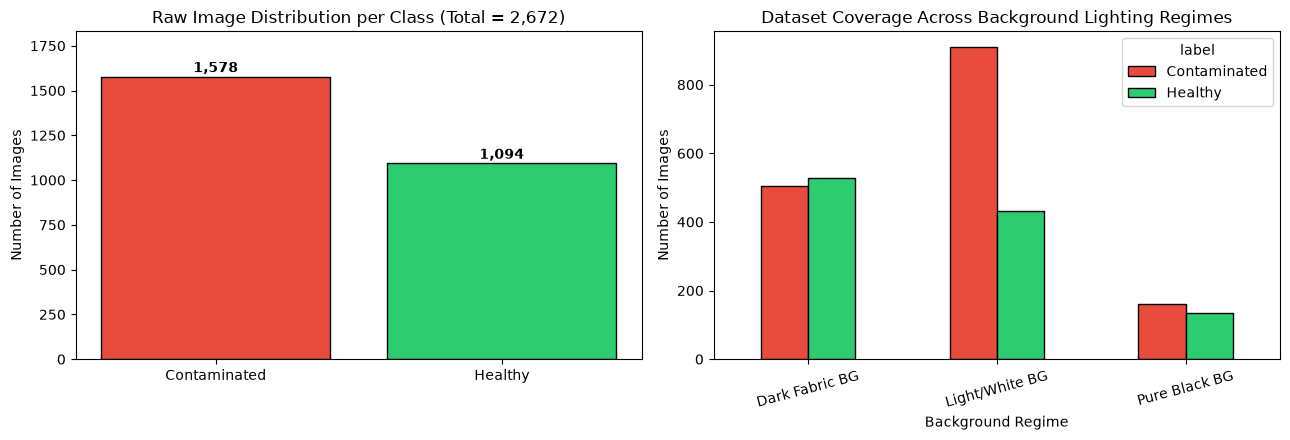

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = df_raw["label"].map(CLASS_LABELS).value_counts()
axes[0].bar(counts.index, counts.values, color=["#e74c3c", "#2ecc71"], edgecolor="black")
axes[0].set_title(f"Raw Image Distribution per Class (Total = {len(df_raw):,})")
axes[0].set_ylabel("Number of Images")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 25, f"{v:,}", ha="center", fontweight="bold")
axes[0].set_ylim(0, max(counts.values) * 1.16)

ct = pd.crosstab(df_raw["bg_regime"], df_raw["label"].map(CLASS_LABELS))
ct.plot(kind="bar", ax=axes[1], color=["#e74c3c", "#2ecc71"], edgecolor="black", rot=15)
axes[1].set_title("Dataset Coverage Across Background Lighting Regimes")
axes[1].set_ylabel("Number of Images")
axes[1].set_xlabel("Background Regime")

plt.tight_layout()
plt.show()

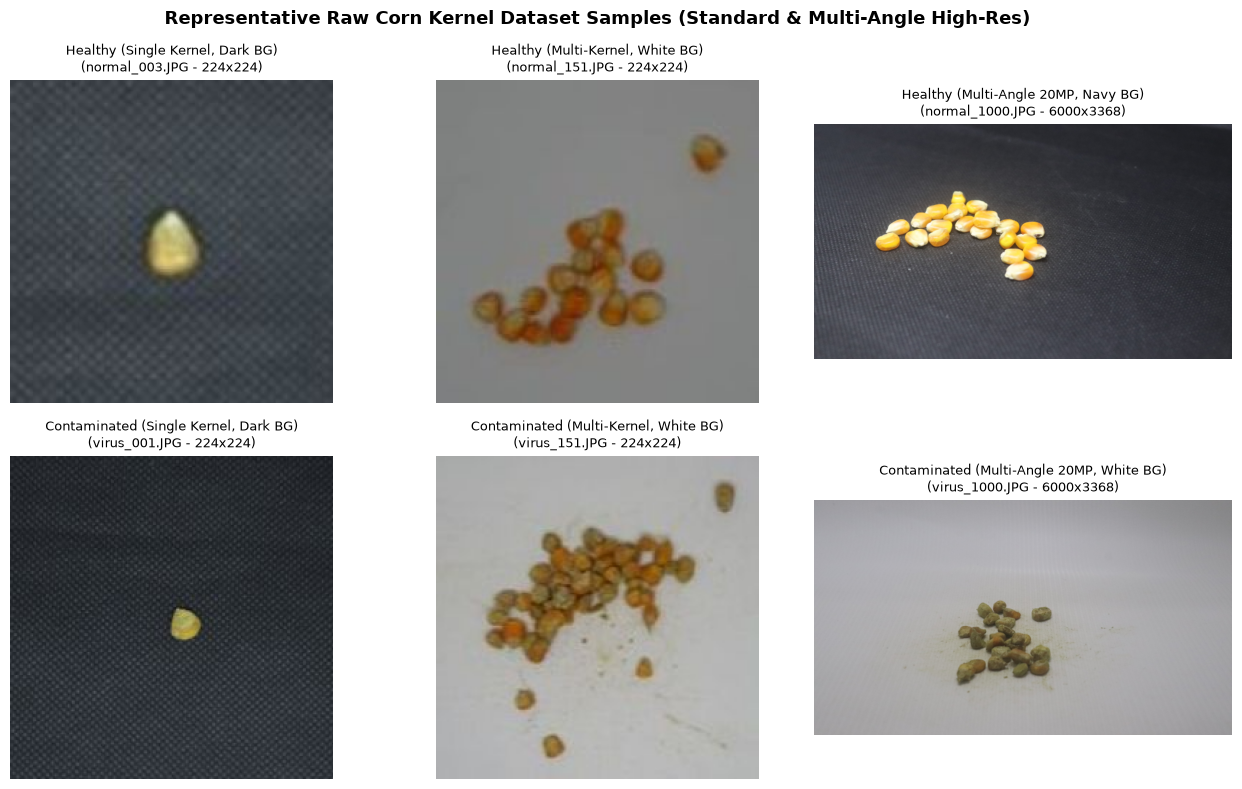

In [3]:
# Visualize representative raw images including the newly added 20MP multi-angle dataset
sample_files = [
    ("sehat", "normal_003.JPG", "Healthy (Single Kernel, Dark BG)"),
    ("sehat", "normal_151.JPG", "Healthy (Multi-Kernel, White BG)"),
    ("sehat", "normal_1000.JPG", "Healthy (Multi-Angle 20MP, Navy BG)"),
    ("terkontaminasi", "virus_001.JPG", "Contaminated (Single Kernel, Dark BG)"),
    ("terkontaminasi", "virus_151.JPG", "Contaminated (Multi-Kernel, White BG)"),
    ("terkontaminasi", "virus_1000.JPG", "Contaminated (Multi-Angle 20MP, White BG)")
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (cls, fname, title) in zip(axes.flat, sample_files):
    fpath = os.path.join(RAW_DIR, cls, fname)
    with Image.open(fpath) as im:
        orig_w, orig_h = im.size
    flag = cv2.IMREAD_REDUCED_COLOR_8 if max(orig_w, orig_h) > 1000 else cv2.IMREAD_COLOR
    img = cv2.imread(fpath, flag)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{title}\n({fname} - {orig_w}x{orig_h})", fontsize=9.5)
    ax.axis("off")

plt.suptitle("Representative Raw Corn Kernel Dataset Samples (Standard & Multi-Angle High-Res)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Key Findings from Dataset Exploration
- **Expanded Dataset Scale:** The dataset now contains **2,672 raw images** (`1,094` in `sehat` and `1,578` in `terkontaminasi`), incorporating `1,656` high-resolution (`6000x3368` and `4496x3000`) multi-angle photographs alongside the `1,016` close-up (`224x224`) images.
- **Automatic Standardization Requirement:** Because raw camera photos arrive at `6000x3368` (16:9 aspect ratio) or `4496x3000`, `CornDiseasePipeline.auto_resize_and_crop()` automatically isolates the corn kernel region of interest (ROI) and standardizes every input image to `224x224` before segmentation.
- **Background Diversity:** The dataset spans dark textured cloth, dark navy-blue fabric (`normal_1000+`), bright white paper (`normal_151+`, `virus_151+`, `virus_1000+`), and pure black backgrounds, requiring warmth-guided polarity-aware segmentation and background-compensated HSV extraction.